In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## roc-curve

**Figure 1: ROC curves of three toxicity classifiers on the test set.** The dashed diagonal marks a chance-level classifier, and each legend entry gives the area under the curve (AUC). Our classifier lies above both baselines at every operating point, reaching an AUC of 0.940 against 0.900 for fine-tuned BERT and 0.830 for logistic regression.

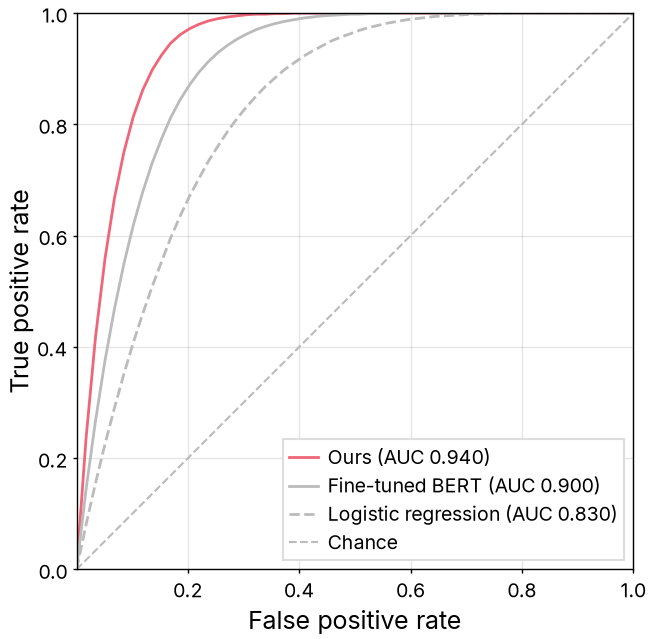

In [2]:
with open("../roc-curve.json") as f:
    curves = json.load(f)

fig, ax = plt.subplots(figsize=(3.25, 3.25))
styles = {
    "Ours": (colors["ours"], "-"),
    "Fine-tuned BERT": (colors["neutral"], "-"),
    "Logistic regression": (colors["neutral"], "--"),
}
for name, (color, linestyle) in styles.items():
    fpr, tpr = curves[name]["fpr"], curves[name]["tpr"]
    auc = np.trapezoid(tpr, fpr)
    ax.plot(fpr, tpr, color=color, linestyle=linestyle, label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=0.75, color=colors["neutral"], zorder=1, label="Chance")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
# the two 0.0 labels collide at the origin, so the x axis starts its labels at 0.2
ax.set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right")

fit_height(fig, ax, aspect=1.0)
fig.savefig("roc-curve.pdf")
fig.savefig("roc-curve.png")
plt.show()

## scaling-curve

**Figure 2: Validation loss against model size for dense and mixture-of-experts (MoE) models.** The x axis is log-scaled, and dashed lines mark each family's loss at the largest size. Our MoE models reach a lower loss than dense models at every size, ending at 2.29 against 2.38 at 12B parameters.

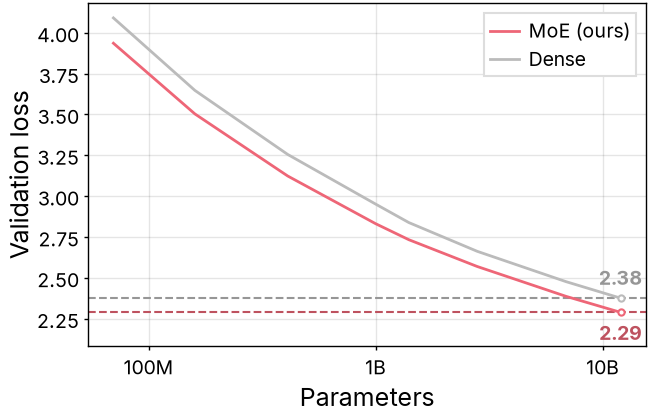

In [3]:
with open("../scaling-curve.json") as f:
    scaling = json.load(f)
params = scaling["params"]

fig, ax = plt.subplots(figsize=(3.25, 2))
ax.plot(params, scaling["MoE (ours)"], color=colors["ours"], label="MoE (ours)")
ax.plot(params, scaling["Dense"], color=colors["neutral"], label="Dense")
mark_value(ax, params[-1], scaling["MoE (ours)"][-1], "2.29", colors["ours"], below=True)
mark_value(ax, params[-1], scaling["Dense"][-1], "2.38", colors["neutral"])

ax.set_xscale("log")
ax.set_xticks([1e8, 1e9, 1e10], labels=["100M", "1B", "10B"])
ax.set_xticks([], minor=True)
ax.set_xlabel("Parameters")
ax.set_ylabel("Validation loss")
ax.legend(loc="upper right")

fit_height(fig, ax, aspect=0.618)
fig.savefig("scaling-curve.pdf")
fig.savefig("scaling-curve.png")
plt.show()